In [1]:
# ============================================================
# CELL 1 — Baseline Configuration
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import sys
import time
import gc

import joblib
import sklearn
import xgboost
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from xgboost import XGBRegressor


# ------------------------------------------------------------
# Project paths
# ------------------------------------------------------------

ROOT = Path.cwd().resolve()

while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data" / "processed"

# Keep the original sampled-model artifacts untouched.
BASELINE_DIR = ROOT / "models" / "baselines_fulltrain"

PREDICTION_DIR = (
    ROOT / "metrics" / "baseline_fulltrain_predictions"
)

FULL_BASELINE_METRICS_DIR = (
    ROOT / "metrics" / "baseline_fulltrain"
)

CACHE_DIR = ROOT / "cache" / "baseline_fulltrain"

FIGURE_DIR = ROOT / "figures" / "exploratory"


# ------------------------------------------------------------
# Dataset configuration
# ------------------------------------------------------------

TARGETS = ["co", "no2", "o3", "pm10", "pm25", "so2"]

DROP_COLS = [
    "datetime_utc",
    "station_code",
    "location_id",
    "source_year",
    "station_name",
    "city",
    "state",
] + TARGETS


train = pd.read_csv(
    DATA_DIR / "train.csv",
    parse_dates=["datetime_utc"],
)

val = pd.read_csv(
    DATA_DIR / "val.csv",
    parse_dates=["datetime_utc"],
)

test = pd.read_csv(
    DATA_DIR / "test.csv",
    parse_dates=["datetime_utc"],
)

FEATURES = [
    c for c in train.columns
    if c not in DROP_COLS
]


# ------------------------------------------------------------
# Reuse policy
# ------------------------------------------------------------

# True: load an existing compatible pollutant checkpoint.
# False: deliberately retrain and replace checkpoints.
REUSE_SAVED_BASELINES = True


print("=" * 65)
print("FULL-TRAINING BASELINE EXPERIMENT")
print("=" * 65)

print("Project root:", ROOT)
print(f"Training rows: {len(train):,}")
print(f"Validation rows: {len(val):,}")
print(f"Test rows: {len(test):,}")
print("Feature count:", len(FEATURES))
print("Targets:", TARGETS)

print("Model artifacts:", BASELINE_DIR)
print("Feature cache:", CACHE_DIR)
print("Metrics:", FULL_BASELINE_METRICS_DIR)

assert len(FEATURES) == 34
assert len(TARGETS) == 6 

FULL-TRAINING BASELINE EXPERIMENT
Project root: C:\Users\vabhi\Downloads\Implementation\Implementation
Training rows: 1,134,975
Validation rows: 243,201
Test rows: 243,238
Feature count: 34
Targets: ['co', 'no2', 'o3', 'pm10', 'pm25', 'so2']
Model artifacts: C:\Users\vabhi\Downloads\Implementation\Implementation\models\baselines_fulltrain
Feature cache: C:\Users\vabhi\Downloads\Implementation\Implementation\cache\baseline_fulltrain
Metrics: C:\Users\vabhi\Downloads\Implementation\Implementation\metrics\baseline_fulltrain


In [2]:
# ============================================================
# CELL 2 — Metrics + AQI Helpers
# ============================================================

AQI_CATS = [
    "Good",
    "Satisfactory",
    "Moderately polluted",
    "Poor",
    "Very Poor",
    "Severe",
]

# CPCB concentration bands expressed as continuous
# interpolation endpoints for each pollutant.
AQI_BP = {
    "pm10": [
        (0, 50, 0, 50),
        (50, 100, 50, 100),
        (100, 250, 100, 200),
        (250, 350, 200, 300),
        (350, 430, 300, 400),
        (430, np.inf, 400, 500),
    ],

    "pm25": [
        (0, 30, 0, 50),
        (30, 60, 50, 100),
        (60, 90, 100, 200),
        (90, 120, 200, 300),
        (120, 250, 300, 400),
        (250, np.inf, 400, 500),
    ],

    "no2": [
        (0, 40, 0, 50),
        (40, 80, 50, 100),
        (80, 180, 100, 200),
        (180, 280, 200, 300),
        (280, 400, 300, 400),
        (400, np.inf, 400, 500),
    ],

    "o3": [
        (0, 50, 0, 50),
        (50, 100, 50, 100),
        (100, 168, 100, 200),
        (168, 208, 200, 300),
        (208, 748, 300, 400),
        (748, np.inf, 400, 500),
    ],

    "co": [
        (0, 1, 0, 50),
        (1, 2, 50, 100),
        (2, 10, 100, 200),
        (10, 17, 200, 300),
        (17, 34, 300, 400),
        (34, np.inf, 400, 500),
    ],

    "so2": [
        (0, 40, 0, 50),
        (40, 80, 50, 100),
        (80, 380, 100, 200),
        (380, 800, 200, 300),
        (800, 1600, 300, 400),
        (1600, np.inf, 400, 500),
    ],
}

# Official CPCB averaging periods.
AQI_WINDOW_HOURS = {
    "co": 8,
    "no2": 24,
    "o3": 8,
    "pm10": 24,
    "pm25": 24,
    "so2": 24,
}


def subindex(values, pollutant):
    """Convert pollutant concentrations into CPCB sub-indices."""

    values = np.asarray(values, dtype=float)

    out = np.full(
        values.shape,
        np.nan,
        dtype=float,
    )

    valid_values = (
        np.isfinite(values)
        & (values >= 0)
    )

    for i, (lo, hi, ilo, ihi) in enumerate(
        AQI_BP[pollutant]
    ):

        if i == 0:
            in_band = (
                (values >= lo)
                & (values <= hi)
            )

        elif np.isfinite(hi):
            in_band = (
                (values > lo)
                & (values <= hi)
            )

        else:
            in_band = values > lo

        use = (
            valid_values
            & in_band
            & np.isnan(out)
        )

        if not np.any(use):
            continue

        if np.isinf(hi):
            out[use] = 500.0

        else:
            out[use] = (
                ilo
                + (ihi - ilo)
                * (values[use] - lo)
                / (hi - lo)
            )

    return np.floor(out)


def evaluate(y_true, y_pred):
    """Calculate standard regression metrics."""

    return {
        "MAE": mean_absolute_error(
            y_true, y_pred
        ),

        "RMSE": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),

        "R2": r2_score(
            y_true, y_pred
        ),
    }


results = []
predictions = {}

print("AQI breakpoint functions ready.")
print("Averaging periods:", AQI_WINDOW_HOURS)

AQI breakpoint functions ready.
Averaging periods: {'co': 8, 'no2': 24, 'o3': 8, 'pm10': 24, 'pm25': 24, 'so2': 24}


In [3]:
# ============================================================
# CELL 3 — Full-Data Preprocessing + Memory-Mapped Cache
# ============================================================

import os

CACHE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

FEATURE_CACHE_CHUNK = 50_000

baseline_train = train  # No large DataFrame copy.

# ------------------------------------------------------------
# Build a cache signature from the source files and schema
# ------------------------------------------------------------

signature_info = {
    "experiment": "full_training_split_v1",

    "train_rows": len(train),
    "validation_rows": len(val),
    "test_rows": len(test),

    "train_file_bytes": (
        DATA_DIR / "train.csv"
    ).stat().st_size,

    "train_file_mtime_ns": (
        DATA_DIR / "train.csv"
    ).stat().st_mtime_ns,

    "test_file_bytes": (
        DATA_DIR / "test.csv"
    ).stat().st_size,

    "test_file_mtime_ns": (
        DATA_DIR / "test.csv"
    ).stat().st_mtime_ns,

    "features": list(FEATURES),
    "targets": list(TARGETS),

    "target_train_rows": {
        target: int(train[target].notna().sum())
        for target in TARGETS
    },
}

BASELINE_SAMPLE_SIGNATURE = hashlib.sha256(
    json.dumps(
        signature_info,
        sort_keys=True,
    ).encode("utf-8")
).hexdigest()

baseline_train_rows = len(train)

# ------------------------------------------------------------
# Fit the imputer only on the complete training split
# ------------------------------------------------------------

print("Fitting median imputer on all training rows...")

imputer = SimpleImputer(
    strategy="median"
)

imputer.fit(
    train[FEATURES]
)

# ------------------------------------------------------------
# Define disk-backed cache files
# ------------------------------------------------------------

X_TRAIN_FULL_PATH = (
    CACHE_DIR / "X_train_full.npy"
)

X_TEST_FULL_PATH = (
    CACHE_DIR / "X_test_full.npy"
)

CACHE_META_PATH = (
    CACHE_DIR / "cache_manifest.json"
)


def train_target_feature_path(target):
    return CACHE_DIR / f"X_train_target_{target}.npy"


def train_target_label_path(target):
    return CACHE_DIR / f"y_train_target_{target}.npy"


expected_cache_files = [
    X_TRAIN_FULL_PATH,
    X_TEST_FULL_PATH,
]

for target in TARGETS:
    expected_cache_files.extend([
        train_target_feature_path(target),
        train_target_label_path(target),
    ])

cache_is_valid = False

if (
    CACHE_META_PATH.exists()
    and all(path.exists() for path in expected_cache_files)
):

    with open(
        CACHE_META_PATH,
        "r",
        encoding="utf-8",
    ) as f:

        old_meta = json.load(f)

    cache_is_valid = (
        old_meta.get("signature")
        == BASELINE_SAMPLE_SIGNATURE
    )


# ------------------------------------------------------------
# Build the cache if missing or incompatible
# ------------------------------------------------------------

if not cache_is_valid:

    print("Building full-training feature cache...")

    train_rows = len(train)
    test_rows = len(test)
    feature_count = len(FEATURES)

    # --------------------------------------------------------
    # A. Full training feature matrix, disk-backed
    # --------------------------------------------------------

    X_train_mm = np.lib.format.open_memmap(
        X_TRAIN_FULL_PATH,
        mode="w+",
        dtype=np.float32,
        shape=(train_rows, feature_count),
    )

    for start in range(
        0, train_rows, FEATURE_CACHE_CHUNK
    ):

        end = min(
            start + FEATURE_CACHE_CHUNK,
            train_rows,
        )

        chunk_df = train.iloc[
            start:end
        ][FEATURES]

        transformed = imputer.transform(
            chunk_df
        )

        X_train_mm[start:end] = np.asarray(
            transformed,
            dtype=np.float32,
        )

        del chunk_df, transformed

    X_train_mm.flush()

    # --------------------------------------------------------
    # B. Full test feature matrix, disk-backed
    # --------------------------------------------------------

    X_test_mm = np.lib.format.open_memmap(
        X_TEST_FULL_PATH,
        mode="w+",
        dtype=np.float32,
        shape=(test_rows, feature_count),
    )

    for start in range(
        0, test_rows, FEATURE_CACHE_CHUNK
    ):

        end = min(
            start + FEATURE_CACHE_CHUNK,
            test_rows,
        )

        transformed = imputer.transform(
            test.iloc[start:end][FEATURES]
        )

        X_test_mm[start:end] = np.asarray(
            transformed,
            dtype=np.float32,
        )

        del transformed

    X_test_mm.flush()
    del X_test_mm

    # --------------------------------------------------------
    # C. Create disk-backed matrices for each pollutant
    # --------------------------------------------------------

    for target in TARGETS:

        valid_positions = np.flatnonzero(
            train[target].notna().to_numpy()
        )

        count = len(valid_positions)

        print(
            f"{target.upper():4} — "
            f"{count:,} eligible training rows"
        )

        target_mm = np.lib.format.open_memmap(
            train_target_feature_path(target),
            mode="w+",
            dtype=np.float32,
            shape=(count, feature_count),
        )

        for start in range(
            0, count, FEATURE_CACHE_CHUNK
        ):

            end = min(
                start + FEATURE_CACHE_CHUNK,
                count,
            )

            positions = valid_positions[
                start:end
            ]

            target_mm[start:end] = (
                X_train_mm[positions]
            )

        target_mm.flush()
        del target_mm

        # Store target labels in float32 format.
        y_all = train[target].to_numpy(
            dtype=np.float32
        )

        np.save(
            train_target_label_path(target),
            y_all[valid_positions],
        )

        del valid_positions, y_all
        gc.collect()

    X_train_mm.flush()
    del X_train_mm
    gc.collect()

    with open(
        CACHE_META_PATH,
        "w",
        encoding="utf-8",
    ) as f:

        json.dump(
            {
                "signature": BASELINE_SAMPLE_SIGNATURE,
                "train_rows": train_rows,
                "test_rows": test_rows,
                "features": FEATURES,
                "targets": TARGETS,
                "target_rows": signature_info[
                    "target_train_rows"
                ],
            },
            f,
            indent=2,
        )

    print("Full-data cache created.")

else:

    print("Reusing compatible full-data feature cache.")


# ------------------------------------------------------------
# Load the shared feature matrices without reading the whole
# matrix into RAM. Target matrices stay disk-backed as well.
# ------------------------------------------------------------

X_train_full = np.load(
    X_TRAIN_FULL_PATH,
    mmap_mode="r",
)

X_test_full = np.load(
    X_TEST_FULL_PATH,
    mmap_mode="r",
)

print("=" * 65)
print("FULL-TRAINING PREPROCESSING COMPLETE")
print("=" * 65)

print("Training features:", X_train_full.shape)
print("Test features:", X_test_full.shape)
print("Training dtype:", X_train_full.dtype)
print("Rows subsampled: No")
print("Imputation fitted on training data only.")

Fitting median imputer on all training rows...
Building full-training feature cache...
CO   — 990,602 eligible training rows
NO2  — 1,031,224 eligible training rows
O3   — 1,025,081 eligible training rows
PM10 — 1,001,915 eligible training rows
PM25 — 1,029,344 eligible training rows
SO2  — 903,666 eligible training rows
Full-data cache created.
FULL-TRAINING PREPROCESSING COMPLETE
Training features: (1134975, 34)
Test features: (243238, 34)
Training dtype: float32
Rows subsampled: No
Imputation fitted on training data only.


In [4]:
# ============================================================
# CELL 4 — Baseline Persistence + Training Helper
# ============================================================

BASELINE_SLUGS = {
    "Ridge": "ridge",
    "Random Forest": "random_forest",
    "XGBoost": "xgboost",
    "MLP": "mlp",
}


def target_model_path(model_name, target):

    return (
        BASELINE_DIR
        / BASELINE_SLUGS[model_name]
        / f"{target}.joblib"
    )


def validate_saved_preprocessing(
    saved,
    current,
    path,
):
    """Validate the saved imputer and optional scaler."""

    if saved.get("kind") != current.get("kind"):
        raise ValueError(
            f"Preprocessing type mismatch: {path}"
        )

    for name, attr in [
        ("imputer", "statistics_"),
        ("scaler", "mean_"),
        ("scaler", "scale_"),
    ]:

        old_obj = saved.get(name)
        new_obj = current.get(name)

        if old_obj is None and new_obj is None:
            continue

        if old_obj is None or new_obj is None:
            raise ValueError(
                f"Preprocessing object mismatch: {name}"
            )

        if (
            hasattr(old_obj, attr)
            and hasattr(new_obj, attr)
            and not np.allclose(
                getattr(old_obj, attr),
                getattr(new_obj, attr),
                rtol=1e-5,
                atol=1e-6,
                equal_nan=True,
            )
        ):

            raise ValueError(
                f"Saved preprocessing parameters differ: {path}"
            )


def save_model_outputs(model_name):

    """Save combined predictions and per-pollutant metrics."""

    slug = BASELINE_SLUGS[model_name]

    frame = test[
        ["datetime_utc", "location_id"]
    ].copy()

    frame.insert(
        0,
        "test_row_index",
        test.index.to_numpy(),
    )

    for target in TARGETS:

        frame[f"actual_{target}"] = (
            test[target].to_numpy()
        )

        frame[f"predicted_{target}"] = (
            predictions[model_name][target]
            .reindex(test.index)
            .to_numpy(dtype=float)
        )

    PREDICTION_DIR.mkdir(
        parents=True,
        exist_ok=True,
    )

    FULL_BASELINE_METRICS_DIR.mkdir(
        parents=True,
        exist_ok=True,
    )

    prediction_path = (
        PREDICTION_DIR
        / f"{slug}_test_predictions.csv"
    )

    metrics_path = (
        FULL_BASELINE_METRICS_DIR
        / f"{slug}_test_metrics.csv"
    )

    frame.to_csv(
        prediction_path,
        index=False,
    )

    pd.DataFrame([
        row for row in results
        if row["model"] == model_name
    ]).to_csv(
        metrics_path,
        index=False,
    )

    print("Predictions saved:", prediction_path)
    print("Metrics saved:", metrics_path)


def run_baseline_target(
    model_name,
    target,
    X_fit,
    y_fit,
    X_eval,
    y_eval,
    eval_index,
    preprocessing,
    hyperparameters,
    estimator_factory,
):
    """
    Fit or load one pollutant model.

    After fitting, save the estimator and its metadata immediately.
    Predictions and metrics are saved before moving to the next target.
    """

    model_path = target_model_path(
        model_name,
        target,
    )

    model_path.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    start_time = time.perf_counter()

    # --------------------------------------------------------
    # Load saved estimator if available
    # --------------------------------------------------------

    if (
        REUSE_SAVED_BASELINES
        and model_path.exists()
    ):

        artifact = joblib.load(model_path)

        if artifact.get("model_name") != model_name:
            raise ValueError(
                f"Model-name mismatch: {model_path}"
            )

        if artifact.get("target") != target:
            raise ValueError(
                f"Target mismatch: {model_path}"
            )

        if artifact["features"] != list(FEATURES):
            raise ValueError(
                f"Feature mismatch: {model_path}"
            )

        if (
            artifact["baseline_sample_signature"]
            != BASELINE_SAMPLE_SIGNATURE
        ):

            raise ValueError(
                f"Saved model belongs to a different dataset: "
                f"{model_path}"
            )

        if artifact["hyperparameters"] != hyperparameters:
            raise ValueError(
                f"Hyperparameter mismatch: {model_path}. "
                "Set REUSE_SAVED_BASELINES=False to retrain."
            )

        if artifact["training_target_rows"] != len(y_fit):
            raise ValueError(
                f"Training-row mismatch: {model_path}"
            )

        validate_saved_preprocessing(
            artifact["preprocessing"],
            preprocessing,
            model_path,
        )

        model = artifact["estimator"]

        del artifact

        print(
            f"Loaded saved {model_name} "
            f"for {target.upper()}."
        )

    else:

        # ----------------------------------------------------
        # Train on all eligible training rows for this target
        # ----------------------------------------------------

        model = estimator_factory()

        print(
            f"Training {model_name} for {target.upper()} "
            f"using {len(y_fit):,} rows..."
        )

        model.fit(
            X_fit,
            y_fit,
        )

        # ----------------------------------------------------
        # Save before prediction or the next training job
        # ----------------------------------------------------

        artifact = {
            "artifact_type": "pollusenseai_baseline_target",
            "format_version": 1,
            "model_name": model_name,
            "target": target,
            "features": list(FEATURES),

            "estimator": model,

            "preprocessing": preprocessing,
            "hyperparameters": hyperparameters,

            "baseline_train_rows": len(train),
            "training_target_rows": len(y_fit),

            "data_split": {
                "train_rows": len(train),
                "validation_rows": len(val),
                "test_rows": len(test),
            },

            "baseline_sample_signature": (
                BASELINE_SAMPLE_SIGNATURE
            ),

            "versions": {
                "python": sys.version.split()[0],
                "numpy": np.__version__,
                "pandas": pd.__version__,
                "scikit_learn": sklearn.__version__,
                "xgboost": xgboost.__version__,
            },

            "saved_at_utc": datetime.now(
                timezone.utc
            ).isoformat(),
        }

        joblib.dump(
            artifact,
            model_path,
            compress=0,
        )

        del artifact

        print("Checkpoint saved:", model_path)

    # --------------------------------------------------------
    # Evaluate current target
    # --------------------------------------------------------

    pred = np.asarray(
        model.predict(X_eval)
    ).reshape(-1)

    if not np.isfinite(pred).all():
        raise ValueError(
            f"Non-finite predictions: {model_name}, {target}"
        )

    scores = evaluate(
        y_eval,
        pred,
    )

    # Avoid duplicate results after a manual cell rerun.
    results[:] = [
        row for row in results
        if not (
            row["model"] == model_name
            and row["target"] == target
        )
    ]

    results.append({
        "model": model_name,
        "target": target,
        **scores,
    })

    predictions.setdefault(
        model_name,
        {},
    )[target] = pd.Series(
        pred,
        index=eval_index,
    )

    # --------------------------------------------------------
    # Save individual pollutant predictions immediately
    # --------------------------------------------------------

    slug = BASELINE_SLUGS[model_name]

    target_pred_dir = PREDICTION_DIR / slug

    target_pred_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    pred_frame = test.loc[
        eval_index,
        ["datetime_utc", "location_id"],
    ].copy()

    pred_frame.insert(
        0,
        "test_row_index",
        eval_index.to_numpy(),
    )

    pred_frame["actual"] = y_eval
    pred_frame["prediction"] = pred

    pred_frame.to_csv(
        target_pred_dir / f"{target}_test_predictions.csv",
        index=False,
    )

    FULL_BASELINE_METRICS_DIR.mkdir(
        parents=True,
        exist_ok=True,
    )

    pd.DataFrame([
        row for row in results
        if row["model"] == model_name
    ]).to_csv(
        FULL_BASELINE_METRICS_DIR
        / f"{slug}_test_metrics.csv",
        index=False,
    )

    elapsed = time.perf_counter() - start_time

    print(
        f"{model_name:15} | {target.upper():4} | "
        f"MAE={scores['MAE']:.4f} | "
        f"RMSE={scores['RMSE']:.4f} | "
        f"R²={scores['R2']:.4f} | "
        f"{elapsed:.1f} sec"
    )

    del model, pred, scores
    gc.collect()


print("Persistence helpers ready.")
print("Full-training cache:", CACHE_DIR)

Persistence helpers ready.
Full-training cache: C:\Users\vabhi\Downloads\Implementation\Implementation\cache\baseline_fulltrain


In [5]:
# ============================================================
# CELL 5 — Ridge Regression
# ============================================================

RIDGE_PARAMS = {
    "alpha": 1.0,
    "solver": "lsqr",
}

RIDGE_PREPROCESSING = {
    "kind": "median_imputer",
    "imputer": imputer,
    "scaler": None,
}

results[:] = [
    r for r in results
    if r["model"] != "Ridge"
]

predictions.pop("Ridge", None)

for target in TARGETS:

    X_fit = np.load(
        train_target_feature_path(target),
        mmap_mode="r",
    )

    y_fit = np.load(
        train_target_label_path(target),
        mmap_mode="r",
    )

    te_mask = test[target].notna().to_numpy()

    X_eval = X_test_full[te_mask]

    y_eval = test.loc[
        te_mask, target
    ].to_numpy(dtype=np.float32)

    eval_index = test.index[te_mask]

    run_baseline_target(
        model_name="Ridge",
        target=target,

        X_fit=X_fit,
        y_fit=y_fit,

        X_eval=X_eval,
        y_eval=y_eval,
        eval_index=eval_index,

        preprocessing=RIDGE_PREPROCESSING,
        hyperparameters=RIDGE_PARAMS,

        estimator_factory=lambda: Ridge(**RIDGE_PARAMS),
    )

    del X_fit, y_fit, X_eval, y_eval
    gc.collect()

save_model_outputs("Ridge")

print("Ridge baseline completed.")

Training Ridge for CO using 990,602 rows...
Checkpoint saved: C:\Users\vabhi\Downloads\Implementation\Implementation\models\baselines_fulltrain\ridge\co.joblib
Ridge           | CO   | MAE=0.2410 | RMSE=0.4314 | R²=0.7999 | 2.0 sec
Training Ridge for NO2 using 1,031,224 rows...
Checkpoint saved: C:\Users\vabhi\Downloads\Implementation\Implementation\models\baselines_fulltrain\ridge\no2.joblib
Ridge           | NO2  | MAE=5.9827 | RMSE=10.9770 | R²=0.8932 | 1.3 sec
Training Ridge for O3 using 1,025,081 rows...
Checkpoint saved: C:\Users\vabhi\Downloads\Implementation\Implementation\models\baselines_fulltrain\ridge\o3.joblib
Ridge           | O3   | MAE=7.5939 | RMSE=14.2325 | R²=0.8657 | 1.5 sec
Training Ridge for PM10 using 1,001,915 rows...
Checkpoint saved: C:\Users\vabhi\Downloads\Implementation\Implementation\models\baselines_fulltrain\ridge\pm10.joblib
Ridge           | PM10 | MAE=29.2534 | RMSE=52.3578 | R²=0.8740 | 1.6 sec
Training Ridge for PM25 using 1,029,344 rows...
Checkpoi

In [10]:
# ============================================================
# CELL 6 — Random Forest
# ============================================================

RF_PARAMS = {
    "n_estimators": 100,
    "max_leaf_nodes": 128,
    "min_samples_leaf": 10,
    "max_features": "sqrt",
    "bootstrap": True,
    "max_samples": None,
    "random_state": 42,
    "n_jobs": 1,
}

RF_PREPROCESSING = {
    "kind": "median_imputer",
    "imputer": imputer,
    "scaler": None,
}

results[:] = [
    r for r in results
    if r["model"] != "Random Forest"
]

predictions.pop("Random Forest", None)

for target in TARGETS:

    X_fit = np.load(
        train_target_feature_path(target),
        mmap_mode="r",
    )

    y_fit = np.load(
        train_target_label_path(target),
        mmap_mode="r",
    )

    te_mask = test[target].notna().to_numpy()

    X_eval = X_test_full[te_mask]

    y_eval = test.loc[
        te_mask, target
    ].to_numpy(dtype=np.float32)

    eval_index = test.index[te_mask]

    run_baseline_target(
        model_name="Random Forest",
        target=target,

        X_fit=X_fit,
        y_fit=y_fit,

        X_eval=X_eval,
        y_eval=y_eval,
        eval_index=eval_index,

        preprocessing=RF_PREPROCESSING,
        hyperparameters=RF_PARAMS,

        estimator_factory=lambda: RandomForestRegressor(
            **RF_PARAMS
        ),
    )

    del X_fit, y_fit, X_eval, y_eval
    gc.collect()

save_model_outputs("Random Forest")

print("Random Forest baseline completed.")

Loaded saved Random Forest for CO.
Random Forest   | CO   | MAE=0.2495 | RMSE=0.4445 | R²=0.7875 | 1.1 sec
Loaded saved Random Forest for NO2.
Random Forest   | NO2  | MAE=7.6160 | RMSE=13.3858 | R²=0.8412 | 1.1 sec
Loaded saved Random Forest for O3.
Random Forest   | O3   | MAE=9.0210 | RMSE=16.3659 | R²=0.8224 | 1.1 sec
Loaded saved Random Forest for PM10.
Random Forest   | PM10 | MAE=33.3706 | RMSE=54.9358 | R²=0.8613 | 1.2 sec
Loaded saved Random Forest for PM25.
Random Forest   | PM25 | MAE=18.4125 | RMSE=34.9547 | R²=0.8712 | 1.2 sec
Loaded saved Random Forest for SO2.
Random Forest   | SO2  | MAE=3.5596 | RMSE=7.4523 | R²=0.6951 | 1.0 sec
Predictions saved: C:\Users\vabhi\Downloads\Implementation\Implementation\metrics\baseline_fulltrain_predictions\random_forest_test_predictions.csv
Metrics saved: C:\Users\vabhi\Downloads\Implementation\Implementation\metrics\baseline_fulltrain\random_forest_test_metrics.csv
Random Forest baseline completed.


In [7]:
# ============================================================
# CELL 7 — XGBoost
# ============================================================

XGB_PARAMS = {
    "n_estimators": 100,
    "learning_rate": 0.05,
    "max_depth": 5,
    "max_bin": 64,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "tree_method": "hist",
    "random_state": 42,
    "n_jobs": 2,
    "verbosity": 0,
}

XGB_PREPROCESSING = {
    "kind": "median_imputer",
    "imputer": imputer,
    "scaler": None,
}

results[:] = [
    r for r in results
    if r["model"] != "XGBoost"
]

predictions.pop("XGBoost", None)

for target in TARGETS:

    X_fit = np.load(
        train_target_feature_path(target),
        mmap_mode="r",
    )

    y_fit = np.load(
        train_target_label_path(target),
        mmap_mode="r",
    )

    te_mask = test[target].notna().to_numpy()

    X_eval = X_test_full[te_mask]

    y_eval = test.loc[
        te_mask, target
    ].to_numpy(dtype=np.float32)

    eval_index = test.index[te_mask]

    run_baseline_target(
        model_name="XGBoost",
        target=target,

        X_fit=X_fit,
        y_fit=y_fit,

        X_eval=X_eval,
        y_eval=y_eval,
        eval_index=eval_index,

        preprocessing=XGB_PREPROCESSING,
        hyperparameters=XGB_PARAMS,

        estimator_factory=lambda: XGBRegressor(
            **XGB_PARAMS
        ),
    )

    del X_fit, y_fit, X_eval, y_eval
    gc.collect()

save_model_outputs("XGBoost")

print("XGBoost baseline completed.")

Training XGBoost for CO using 990,602 rows...
Checkpoint saved: C:\Users\vabhi\Downloads\Implementation\Implementation\models\baselines_fulltrain\xgboost\co.joblib
XGBoost         | CO   | MAE=0.1854 | RMSE=0.3760 | R²=0.8480 | 10.8 sec
Training XGBoost for NO2 using 1,031,224 rows...
Checkpoint saved: C:\Users\vabhi\Downloads\Implementation\Implementation\models\baselines_fulltrain\xgboost\no2.joblib
XGBoost         | NO2  | MAE=6.0600 | RMSE=11.7761 | R²=0.8771 | 10.0 sec
Training XGBoost for O3 using 1,025,081 rows...
Checkpoint saved: C:\Users\vabhi\Downloads\Implementation\Implementation\models\baselines_fulltrain\xgboost\o3.joblib
XGBoost         | O3   | MAE=6.7556 | RMSE=13.7163 | R²=0.8752 | 9.5 sec
Training XGBoost for PM10 using 1,001,915 rows...
Checkpoint saved: C:\Users\vabhi\Downloads\Implementation\Implementation\models\baselines_fulltrain\xgboost\pm10.joblib
XGBoost         | PM10 | MAE=27.4010 | RMSE=49.3712 | R²=0.8880 | 9.8 sec
Training XGBoost for PM25 using 1,029,

In [8]:
# ============================================================
# CELL 8 — MLP
# ============================================================

MLP_PARAMS = {
    "hidden_layer_sizes": (64, 32),
    "activation": "relu",
    "solver": "adam",
    "batch_size": 4096,
    "learning_rate_init": 0.001,
    "max_iter": 20,
    "early_stopping": True,
    "validation_fraction": 0.05,
    "n_iter_no_change": 3,
    "tol": 1e-3,
    "random_state": 42,
}

# ------------------------------------------------------------
# Fit StandardScaler incrementally over all training rows
# ------------------------------------------------------------

mlp_scaler = StandardScaler()

for start in range(
    0, len(train), FEATURE_CACHE_CHUNK
):

    end = min(
        start + FEATURE_CACHE_CHUNK,
        len(train),
    )

    mlp_scaler.partial_fit(
        X_train_full[start:end]
    )

# ------------------------------------------------------------
# Transform the test matrix into a disk-backed array
# ------------------------------------------------------------

X_TEST_MLP_PATH = CACHE_DIR / "X_test_mlp.npy"

X_test_mlp_mm = np.lib.format.open_memmap(
    X_TEST_MLP_PATH,
    mode="w+",
    dtype=np.float32,
    shape=X_test_full.shape,
)

for start in range(
    0, len(test), FEATURE_CACHE_CHUNK
):

    end = min(
        start + FEATURE_CACHE_CHUNK,
        len(test),
    )

    X_test_mlp_mm[start:end] = (
        mlp_scaler.transform(
            X_test_full[start:end]
        ).astype(np.float32, copy=False)
    )

X_test_mlp_mm.flush()
del X_test_mlp_mm
gc.collect()

X_test_mlp = np.load(
    X_TEST_MLP_PATH,
    mmap_mode="r",
)

MLP_PREPROCESSING = {
    "kind": "median_imputer_then_standard_scaler",
    "imputer": imputer,
    "scaler": mlp_scaler,
}

results[:] = [
    r for r in results
    if r["model"] != "MLP"
]

predictions.pop("MLP", None)

MLP_WORK_PATH = CACHE_DIR / "X_train_mlp_work.npy"

for target in TARGETS:

    X_fit_raw = np.load(
        train_target_feature_path(target),
        mmap_mode="r",
    )

    y_fit = np.load(
        train_target_label_path(target),
        mmap_mode="r",
    )

    model_path = target_model_path(
        "MLP", target
    )

    # If loading a saved estimator, only the training row count is
    # needed by the helper. No scaled training matrix is necessary.
    should_train = not (
        REUSE_SAVED_BASELINES
        and model_path.exists()
    )

    if should_train:

        # Create one temporary scaled training matrix on disk.
        # Reuse this temporary file for each pollutant.
        if MLP_WORK_PATH.exists():
            MLP_WORK_PATH.unlink()

        X_mlp_mm = np.lib.format.open_memmap(
            MLP_WORK_PATH,
            mode="w+",
            dtype=np.float32,
            shape=X_fit_raw.shape,
        )

        for start in range(
            0, len(y_fit), FEATURE_CACHE_CHUNK
        ):

            end = min(
                start + FEATURE_CACHE_CHUNK,
                len(y_fit),
            )

            X_mlp_mm[start:end] = (
                mlp_scaler.transform(
                    X_fit_raw[start:end]
                ).astype(np.float32, copy=False)
            )

        X_mlp_mm.flush()
        del X_mlp_mm
        gc.collect()

        X_fit = np.load(
            MLP_WORK_PATH,
            mmap_mode="r",
        )

    else:
        X_fit = X_fit_raw

    te_mask = test[target].notna().to_numpy()

    X_eval = X_test_mlp[te_mask]

    y_eval = test.loc[
        te_mask, target
    ].to_numpy(dtype=np.float32)

    eval_index = test.index[te_mask]

    run_baseline_target(
        model_name="MLP",
        target=target,

        X_fit=X_fit,
        y_fit=y_fit,

        X_eval=X_eval,
        y_eval=y_eval,
        eval_index=eval_index,

        preprocessing=MLP_PREPROCESSING,
        hyperparameters=MLP_PARAMS,

        estimator_factory=lambda: MLPRegressor(
            **MLP_PARAMS
        ),
    )

    del X_fit, X_fit_raw, y_fit, X_eval, y_eval
    gc.collect()

    if MLP_WORK_PATH.exists():
        MLP_WORK_PATH.unlink()

save_model_outputs("MLP")

print("MLP baseline completed.")

Training MLP for CO using 990,602 rows...
Checkpoint saved: C:\Users\vabhi\Downloads\Implementation\Implementation\models\baselines_fulltrain\mlp\co.joblib
MLP             | CO   | MAE=0.1886 | RMSE=0.3645 | R²=0.8572 | 22.5 sec
Training MLP for NO2 using 1,031,224 rows...
Checkpoint saved: C:\Users\vabhi\Downloads\Implementation\Implementation\models\baselines_fulltrain\mlp\no2.joblib
MLP             | NO2  | MAE=5.8438 | RMSE=10.4898 | R²=0.9025 | 10.8 sec
Training MLP for O3 using 1,025,081 rows...


C:\Users\vabhi\AppData\Roaming\Python\Python311\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


Checkpoint saved: C:\Users\vabhi\Downloads\Implementation\Implementation\models\baselines_fulltrain\mlp\o3.joblib
MLP             | O3   | MAE=6.4931 | RMSE=12.6736 | R²=0.8935 | 23.2 sec
Training MLP for PM10 using 1,001,915 rows...
Checkpoint saved: C:\Users\vabhi\Downloads\Implementation\Implementation\models\baselines_fulltrain\mlp\pm10.joblib
MLP             | PM10 | MAE=27.9450 | RMSE=50.4851 | R²=0.8829 | 17.7 sec
Training MLP for PM25 using 1,029,344 rows...
Checkpoint saved: C:\Users\vabhi\Downloads\Implementation\Implementation\models\baselines_fulltrain\mlp\pm25.joblib
MLP             | PM25 | MAE=14.5475 | RMSE=29.7916 | R²=0.9065 | 14.7 sec
Training MLP for SO2 using 903,666 rows...


C:\Users\vabhi\AppData\Roaming\Python\Python311\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


Checkpoint saved: C:\Users\vabhi\Downloads\Implementation\Implementation\models\baselines_fulltrain\mlp\so2.joblib
MLP             | SO2  | MAE=2.6459 | RMSE=5.9757 | R²=0.8040 | 20.3 sec
Predictions saved: C:\Users\vabhi\Downloads\Implementation\Implementation\metrics\baseline_fulltrain_predictions\mlp_test_predictions.csv
Metrics saved: C:\Users\vabhi\Downloads\Implementation\Implementation\metrics\baseline_fulltrain\mlp_test_metrics.csv
MLP baseline completed.


COMMON-TEST-ROW REGRESSION COMPARISON
        Model Pollutant       MAE      RMSE       R2  Common_valid_test_rows
     GAT-LSTM        co  0.154622  0.340344 0.875074                  188999
        Ridge        co  0.236792  0.422474 0.807506                  188999
Random Forest        co  0.245345  0.436151 0.794841                  188999
      XGBoost        co  0.180180  0.364807 0.856469                  188999
          MLP        co  0.183422  0.351852 0.866483                  188999
     GAT-LSTM       no2  4.957168  9.168871 0.925033                  190746
        Ridge       no2  5.865881 10.515395 0.901397                  190746
Random Forest       no2  7.525518 13.074656 0.847559                  190746
      XGBoost       no2  5.959890 11.441168 0.883270                  190746
          MLP       no2  5.733070 10.033021 0.910236                  190746
     GAT-LSTM        o3  5.159183 10.976510 0.919588                  189143
        Ridge        o3  7.373157 13.4

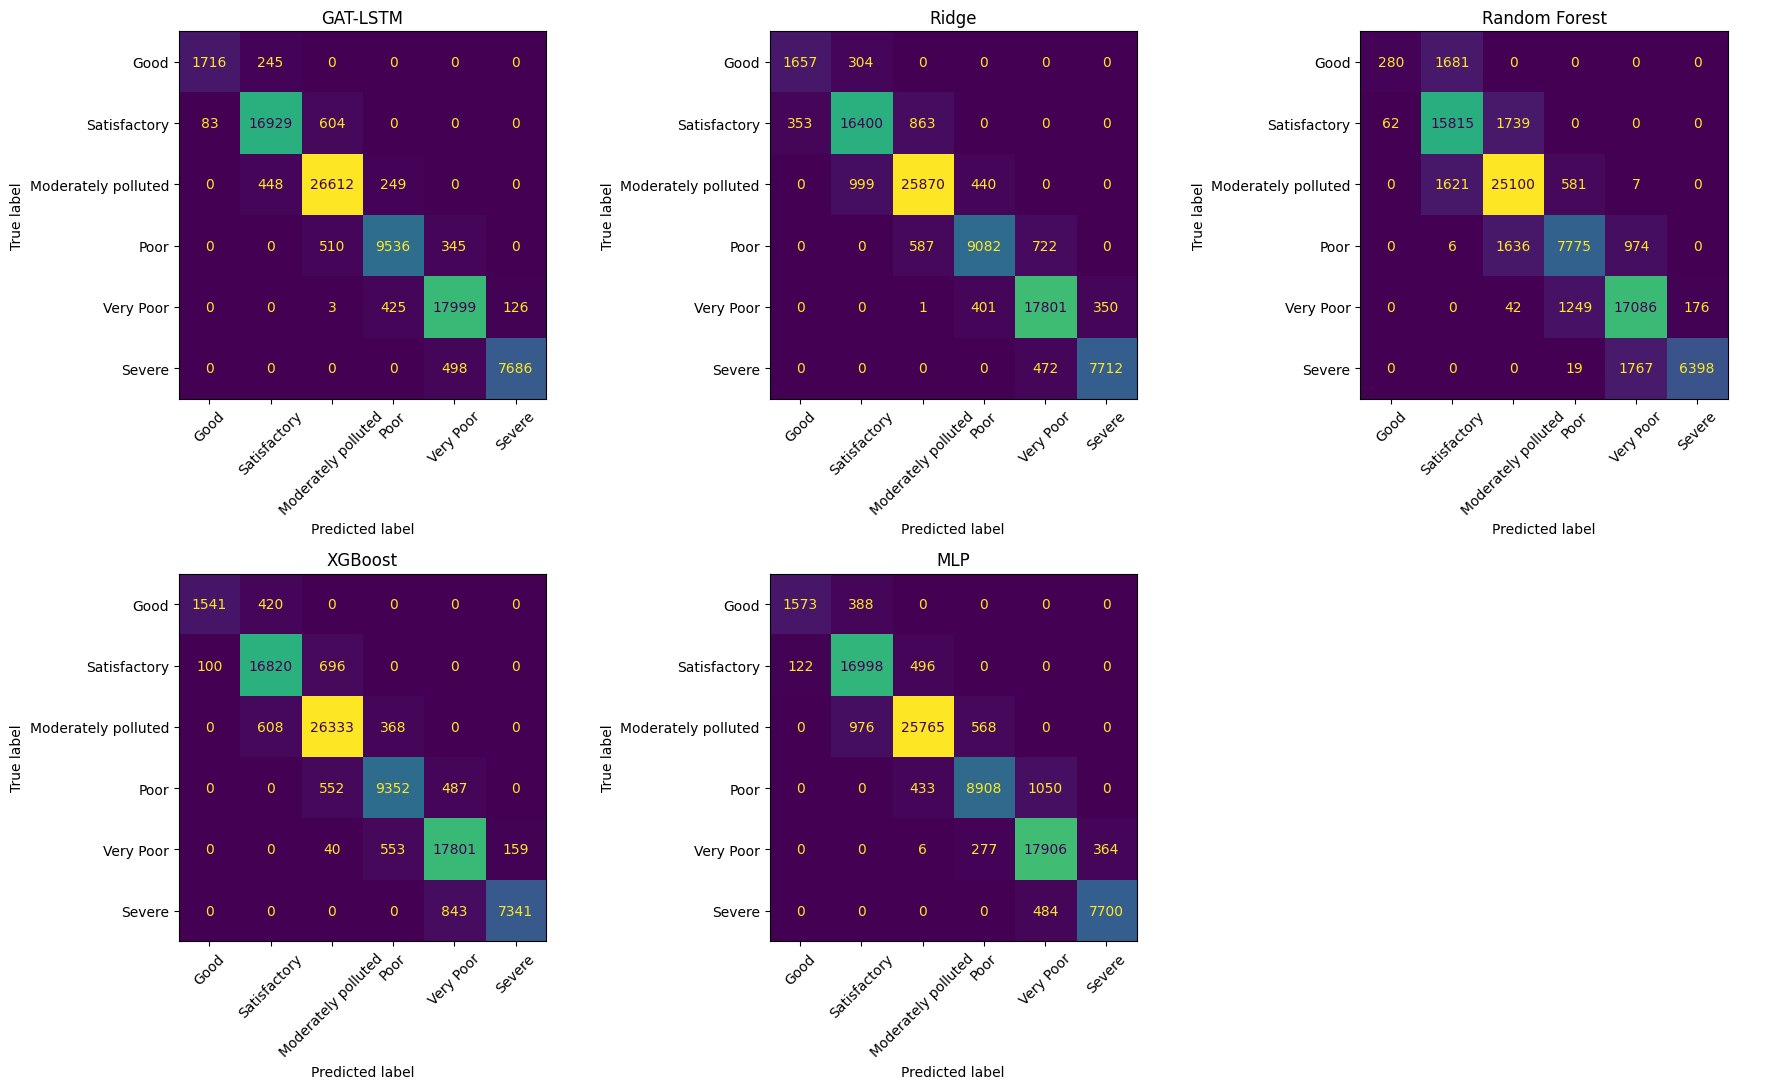


Saved final results:
C:\Users\vabhi\Downloads\Implementation\Implementation\metrics\baseline_fulltrain\baseline_per_pollutant_fulltrain.csv
C:\Users\vabhi\Downloads\Implementation\Implementation\metrics\baseline_fulltrain\baseline_vs_gat_lstm_common_regression.csv
C:\Users\vabhi\Downloads\Implementation\Implementation\metrics\baseline_fulltrain\baseline_vs_gat_lstm_common_aqi.csv
C:\Users\vabhi\Downloads\Implementation\Implementation\metrics\baseline_fulltrain\common_aqi_windows_all_models.csv


In [15]:
# ============================================================
# CELL 9 — Final Metrics + Common GAT-LSTM Comparison
# ============================================================

import joblib
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)


# ------------------------------------------------------------
# 1. Save the complete-training baseline metrics
# ------------------------------------------------------------

reg_results = pd.DataFrame(results)

reg_results = reg_results.drop_duplicates(
    subset=["model", "target"],
    keep="last",
)

reg_results = reg_results.sort_values(
    ["model", "target"]
).reset_index(drop=True)

if len(reg_results) != len(BASELINE_SLUGS) * len(TARGETS):
    raise ValueError(
        "Not all baseline regressors have completed evaluation. "
        "Expected six pollutant results per baseline."
    )

FULL_BASELINE_METRICS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

reg_results.to_csv(
    FULL_BASELINE_METRICS_DIR
    / "baseline_per_pollutant_fulltrain.csv",
    index=False,
)


# ------------------------------------------------------------
# 2. Load existing GAT-LSTM test predictions
# ------------------------------------------------------------

MODEL_DIR = ROOT / "models"

CFG_PATH = MODEL_DIR / "gat_lstm_config.pkl"

FULL_PRED_PATH = (
    MODEL_DIR / "gat_lstm_test_predictions.npy"
)

FULL_MASK_PATH = (
    MODEL_DIR / "gat_lstm_test_mask.npy"
)

TIMES_PATH = (
    MODEL_DIR / "gat_lstm_test_times.npy"
)

for path in [
    CFG_PATH,
    FULL_PRED_PATH,
    FULL_MASK_PATH,
]:

    if not path.exists():
        raise FileNotFoundError(
            f"Required GAT-LSTM evaluation artifact missing: {path}"
        )

cfg = joblib.load(CFG_PATH)

STATIONS = list(cfg["station_list"])
SEQ_LEN = int(cfg["seq_len"])

if list(cfg["targets"]) != TARGETS:
    raise ValueError(
        "GAT-LSTM target order differs from baseline target order."
    )

full_pred = np.load(
    FULL_PRED_PATH,
    allow_pickle=False,
)

full_mask = np.load(
    FULL_MASK_PATH,
    allow_pickle=False,
).astype(bool)

if full_pred.shape != full_mask.shape:
    raise ValueError(
        "GAT-LSTM prediction/mask shapes do not match."
    )

if (
    full_pred.ndim != 3
    or full_pred.shape[1] != len(STATIONS)
    or full_pred.shape[2] != len(TARGETS)
):

    raise ValueError(
        f"Unexpected GAT-LSTM test prediction shape: "
        f"{full_pred.shape}"
    )


# ------------------------------------------------------------
# 3. Recover timestamps and station identifiers
# ------------------------------------------------------------

q = test[
    ["datetime_utc", "location_id"] + TARGETS
].copy()

q["_row_index"] = test.index.to_numpy()

q["time_key"] = (
    pd.to_datetime(
        q["datetime_utc"],
        utc=True,
    )
    .dt.tz_localize(None)
)

q["loc_key"] = q["location_id"].astype(str)

if TIMES_PATH.exists():

    full_times = pd.DatetimeIndex(
        pd.to_datetime(
            np.load(
                TIMES_PATH,
                allow_pickle=False,
            ),
            utc=True,
        ).tz_localize(None)
    )

else:

    # Notebook 7's sequence evaluator predicts after the first
    # SEQ_LEN observations used to construct the input sequence.
    all_times = pd.DatetimeIndex(
        q["time_key"].drop_duplicates().sort_values()
    )

    full_times = all_times[SEQ_LEN:]


if len(full_times) != full_pred.shape[0]:
    raise ValueError(
        "GAT-LSTM timestamps cannot be aligned with predictions. "
        f"Times={len(full_times)}, predictions={full_pred.shape[0]}. "
        "Run Notebook 7's evaluation/save cell to regenerate "
        "gat_lstm_test_times.npy."
    )


# ------------------------------------------------------------
# 4. Add baseline predictions to the shared test table
# ------------------------------------------------------------

MODELS_FOR_COMPARISON = [
    "GAT-LSTM",
    "Ridge",
    "Random Forest",
    "XGBoost",
    "MLP",
]

MODEL_SLUG = {
    "GAT-LSTM": "gat_lstm",
    "Ridge": "ridge",
    "Random Forest": "random_forest",
    "XGBoost": "xgboost",
    "MLP": "mlp",
}

for model_name in [
    "Ridge",
    "Random Forest",
    "XGBoost",
    "MLP",
]:

    if model_name not in predictions:
        raise ValueError(
            f"Missing in-memory predictions for {model_name}. "
            "Run or load its six pollutant models first."
        )

    for target in TARGETS:

        if target not in predictions[model_name]:
            raise ValueError(
                f"Missing {model_name} predictions for {target}."
            )

        column = (
            f"pred__{MODEL_SLUG[model_name]}__{target}"
        )

        q[column] = (
            predictions[model_name][target]
            .reindex(test.index)
            .to_numpy(dtype=float)
        )


# ------------------------------------------------------------
# 5. Align GAT-LSTM predictions by exact timestamp + station
# ------------------------------------------------------------

gat_frame = pd.DataFrame({
    "time_key": np.repeat(
        full_times.to_numpy(),
        len(STATIONS),
    ),

    "loc_key": np.tile(
        np.asarray(STATIONS, dtype=str),
        len(full_times),
    ),
})

for k, target in enumerate(TARGETS):

    values = full_pred[:, :, k].reshape(-1).astype(float)

    valid_mask = full_mask[:, :, k].reshape(-1)

    # A prediction whose target mask is false cannot support
    # a supervised evaluation window.
    values[~valid_mask] = np.nan

    gat_frame[
        f"pred__gat_lstm__{target}"
    ] = values


if gat_frame.duplicated(
    ["time_key", "loc_key"]
).any():

    raise ValueError(
        "Duplicate timestamp/station rows in the GAT-LSTM artifacts."
    )


q = q.merge(
    gat_frame,
    on=["time_key", "loc_key"],
    how="left",
    validate="one_to_one",
)

q = q.sort_values(
    ["loc_key", "time_key"]
).reset_index(drop=True)


# ------------------------------------------------------------
# 6. Regression comparison on common valid test rows
# ------------------------------------------------------------

regression_rows = []

for target in TARGETS:

    common_mask = np.isfinite(
        q[target].to_numpy(dtype=float)
    )

    # Require a valid prediction from every compared model
    # for each pollutant's common regression cohort.
    for model_name in MODELS_FOR_COMPARISON:

        pred_col = (
            f"pred__{MODEL_SLUG[model_name]}__{target}"
        )

        common_mask &= np.isfinite(
            q[pred_col].to_numpy(dtype=float)
        )

    yt = q.loc[
        common_mask, target
    ].to_numpy(dtype=float)

    if len(yt) == 0:
        raise ValueError(
            f"No common regression test rows for {target}."
        )

    for model_name in MODELS_FOR_COMPARISON:

        pred_col = (
            f"pred__{MODEL_SLUG[model_name]}__{target}"
        )

        yp = q.loc[
            common_mask, pred_col
        ].to_numpy(dtype=float)

        regression_rows.append({
            "Model": model_name,
            "Pollutant": target,
            **evaluate(yt, yp),
            "Common_valid_test_rows": len(yt),
        })


common_regression = pd.DataFrame(
    regression_rows
)

common_regression.to_csv(
    FULL_BASELINE_METRICS_DIR
    / "baseline_vs_gat_lstm_common_regression.csv",
    index=False,
)

print("=" * 75)
print("COMMON-TEST-ROW REGRESSION COMPARISON")
print("=" * 75)

print(
    common_regression.to_string(index=False)
)


# ------------------------------------------------------------
# 7. Build CPCB-period rolling concentration averages
# ------------------------------------------------------------

for target in TARGETS:

    window = AQI_WINDOW_HOURS[target]

    q[f"actual_roll__{target}"] = (
        q.groupby(
            "loc_key",
            sort=False,
        )[target]
        .transform(
            lambda s: s.rolling(
                window=window,
                min_periods=window,
            ).mean()
        )
    )

    for model_name in MODELS_FOR_COMPARISON:

        pred_col = (
            f"pred__{MODEL_SLUG[model_name]}__{target}"
        )

        roll_col = (
            f"pred_roll__{MODEL_SLUG[model_name]}__{target}"
        )

        # AQI calculation uses physically valid concentrations.
        # Clip negative hourly predictions to zero before averaging.
        # Raw predictions remain unchanged for regression evaluation.

        q[roll_col] = (
            q.groupby(
                "loc_key",
                sort=False,
            )[pred_col]
            .transform(
                lambda s: s.clip(lower=0).rolling(
                    window=window,
                    min_periods=window,
                ).mean()
            )
        )


# ------------------------------------------------------------
# 8. One common valid AQI window set across all five models
# ------------------------------------------------------------

common_aqi_mask = np.ones(
    len(q),
    dtype=bool,
)

# Every actual pollutant must have its complete averaging window.
for target in TARGETS:

    actual_roll_col = f"actual_roll__{target}"

    common_aqi_mask &= np.isfinite(
        q[actual_roll_col].to_numpy(dtype=float)
    )


# Every model must also have complete predicted averages for
# every pollutant at each accepted station-time window.
for model_name in MODELS_FOR_COMPARISON:

    for target in TARGETS:

        roll_col = (
            f"pred_roll__{MODEL_SLUG[model_name]}__{target}"
        )

        common_aqi_mask &= np.isfinite(
            q[roll_col].to_numpy(dtype=float)
        )


common_windows = q.loc[
    common_aqi_mask
].copy()

if common_windows.empty:
    raise ValueError(
        "No common valid CPCB-period AQI windows remain. "
        "Check data coverage and alignment."
    )

print("\nCommon valid AQI windows:", len(common_windows))
print("Averaging periods:", AQI_WINDOW_HOURS)


# ------------------------------------------------------------
# 9. Derive the actual AQI category once
# ------------------------------------------------------------

actual_rolling = common_windows[
    [f"actual_roll__{t}" for t in TARGETS]
].to_numpy(dtype=float)

actual_subindices = np.column_stack([
    subindex(
        actual_rolling[:, k],
        target,
    )
    for k, target in enumerate(TARGETS)
])

actual_aqi = np.max(
    actual_subindices,
    axis=1,
)

AQI_BINS = [
    -np.inf, 50, 100, 200, 300, 400, np.inf
]

y_true_aqi = pd.cut(
    actual_aqi,
    bins=AQI_BINS,
    labels=AQI_CATS,
    include_lowest=True,
)


# ------------------------------------------------------------
# 10. Evaluate all models on the identical classification cohort
# ------------------------------------------------------------


aqi_rows = []
confusion_matrices = {}
predicted_aqi_by_model = {}
predicted_categories_by_model = {}

# Preserve the original labels. Never shorten or overwrite them.
actual_categories = pd.Series(
    y_true_aqi,
    index=common_windows.index,
    dtype="object",
)

# First calculate predictions for every model.
# This allows us to establish ONE shared classification cohort.

for model_name in MODELS_FOR_COMPARISON:

    predicted_rolling = common_windows[
        [
            f"pred_roll__{MODEL_SLUG[model_name]}__{t}"
            for t in TARGETS
        ]
    ].to_numpy(dtype=float)

    predicted_subindices = np.column_stack([
        subindex(
            predicted_rolling[:, k],
            target,
        )
        for k, target in enumerate(TARGETS)
    ])

    predicted_aqi = np.max(
        predicted_subindices,
        axis=1,
    )

    predicted_categories = pd.Series(
        pd.cut(
            predicted_aqi,
            bins=AQI_BINS,
            labels=AQI_CATS,
            include_lowest=True,
        ),
        index=common_windows.index,
        dtype="object",
    )

    predicted_aqi_by_model[model_name] = predicted_aqi
    predicted_categories_by_model[model_name] = (
        predicted_categories
    )

    invalid_count = int(predicted_categories.isna().sum())

    print(
        f"{model_name}: invalid predicted AQI categories = "
        f"{invalid_count:,} / {len(common_windows):,}"
    )


# Establish the same valid rows for every model.
common_classification_mask = actual_categories.notna().to_numpy()

for model_name in MODELS_FOR_COMPARISON:

    model_categories = predicted_categories_by_model[model_name]

    common_classification_mask &= (
        model_categories.notna().to_numpy()
    )

n_common_classification = int(
    common_classification_mask.sum()
)

if n_common_classification == 0:
    raise ValueError(
        "No common valid AQI classification rows remain. "
        "Inspect the invalid predicted AQI values above."
    )

print(
    "\nCommon valid classification rows across all models:",
    f"{n_common_classification:,} / {len(common_windows):,}",
)


# Evaluate each model on exactly those shared rows.
for model_name in MODELS_FOR_COMPARISON:

    model_categories = predicted_categories_by_model[model_name]

    y_true_valid = (
        actual_categories.iloc[
            np.flatnonzero(common_classification_mask)
        ]
        .astype(str)
        .to_numpy()
    )

    y_pred_valid = (
        model_categories.iloc[
            np.flatnonzero(common_classification_mask)
        ]
        .astype(str)
        .to_numpy()
    )

    cm = confusion_matrix(
        y_true_valid,
        y_pred_valid,
        labels=AQI_CATS,
    )

    confusion_matrices[model_name] = cm

    aqi_rows.append({
        "Model": model_name,

        "Accuracy": accuracy_score(
            y_true_valid,
            y_pred_valid,
        ),

        "Macro_precision": precision_score(
            y_true_valid,
            y_pred_valid,
            labels=AQI_CATS,
            average="macro",
            zero_division=0,
        ),

        "Macro_recall": recall_score(
            y_true_valid,
            y_pred_valid,
            labels=AQI_CATS,
            average="macro",
            zero_division=0,
        ),

        "Macro_F1": f1_score(
            y_true_valid,
            y_pred_valid,
            labels=AQI_CATS,
            average="macro",
            zero_division=0,
        ),

        "Common_valid_AQI_windows": n_common_classification,
    })

    # Keep the export aligned with every row in common_windows.
    # Invalid predictions are explicitly marked, not silently
    # removed from the exported table.
    aqi_export[
        f"predicted_AQI__{MODEL_SLUG[model_name]}"
    ] = predicted_aqi_by_model[model_name]

    aqi_export[
        f"y_pred_aqi__{MODEL_SLUG[model_name]}"
    ] = (
        model_categories
        .astype("string")
        .fillna("INVALID")
        .to_numpy(dtype=str)
    )

aqi_comparison = pd.DataFrame(aqi_rows)

aqi_comparison.to_csv(
    FULL_BASELINE_METRICS_DIR
    / "baseline_vs_gat_lstm_common_aqi.csv",
    index=False,
)

aqi_export.to_csv(
    FULL_BASELINE_METRICS_DIR
    / "common_aqi_windows_all_models.csv",
    index=False,
)

# Persist confusion matrices in a portable tabular format.
for model_name, cm in confusion_matrices.items():

    cm_df = pd.DataFrame(
        cm,
        index=[f"Actual_{c}" for c in AQI_CATS],
        columns=[f"Predicted_{c}" for c in AQI_CATS],
    )

    cm_df.to_csv(
        FULL_BASELINE_METRICS_DIR
        / f"confusion_matrix_{MODEL_SLUG[model_name]}.csv"
    )


print("\n" + "=" * 75)
print("COMMON-WINDOW CPCB-PERIOD AQI CLASSIFICATION COMPARISON")
print("=" * 75)

print(
    aqi_comparison.to_string(index=False)
)


# ------------------------------------------------------------
# 11. Plot all five confusion matrices on the same sample set
# ------------------------------------------------------------

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

fig, axes = plt.subplots(
    2, 3,
    figsize=(18, 11),
)

for ax, model_name in zip(
    axes.flatten(),
    MODELS_FOR_COMPARISON,
):

    ConfusionMatrixDisplay(
        confusion_matrix=confusion_matrices[model_name],
        display_labels=AQI_CATS,
    ).plot(
        ax=ax,
        values_format="d",
        colorbar=False,
        xticks_rotation=45,
    )

    ax.set_title(model_name)


axes.flatten()[-1].axis("off")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "fig_common_aqi_confusion_matrices_all_models.png",
    dpi=400,
    bbox_inches="tight",
)

plt.show()


print("\nSaved final results:")
print(
    FULL_BASELINE_METRICS_DIR
    / "baseline_per_pollutant_fulltrain.csv"
)
print(
    FULL_BASELINE_METRICS_DIR
    / "baseline_vs_gat_lstm_common_regression.csv"
)
print(
    FULL_BASELINE_METRICS_DIR
    / "baseline_vs_gat_lstm_common_aqi.csv"
)
print(
    FULL_BASELINE_METRICS_DIR
    / "common_aqi_windows_all_models.csv"
)